## Introduction
For the barnacle problem, one idea that pops up to my mind is using machine learning. My thought process would be following: using the masks, get the information about barnacles, represent them as a numeric data, and feed them into a machine learning model, most probably random forest. The reason for this is this: in an image, there will be a lot of barnacles present. It is am tedious process to select every single them manually. If we can develop a model that can automatically do it for us with high accuracy, the team can save unbelievable amounts of time. 

One critical subtask, maybe the most important one, is preparing the training data set for model training. This involves identifying region of interests that will act like the ground truth (regions where we know for sure that barnacles exists), converting these regions to numeric data that can be both visualised and converted in such a way that it can be used in training as input. Later, this model would allow us to obtain results for regions with barnacles for images that were not used before. As such, I will be following a model-based approach to this problem rather than visualisation. I will only use visualisation as a way of making sense of the data and ensuring it is implementable. 

In [41]:
#This notebook will act like a layout of my project. The main target here is that I explain my thought process and test/experiment lines of code for implementation while learning at the same time. 
#Refer to this notebook for explanations and my thought process and to access the code.  

#First,let's import necessary libraries. 
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

(1453, 1449, 3) uint8 6316191 0 255


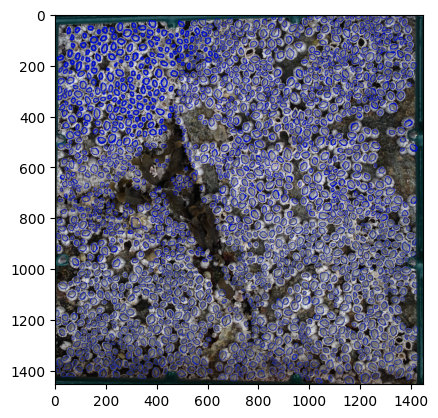

In [42]:
#I did not do image analysis before. Hence, this will be the first time I will be doing it as well.
#Most of the information I use are obtained from opencv documentation and Stack Overflow forums. 
#I use AI only as a tool for explaining some of the functions at points I get stuck. 

#When we scan an image using opencv2, it stores the image as an n-dimensional numpy array 
#In this array, many properties like shape, data type, size are stored. 
img1 = cv2.imread("data/masked_img1.png")
print(img1.shape, img1.dtype, img1.size,img1.min(), img1.max())
#One important information: opencv uses BGR instead of RGB. So, we convert from BGR to RGB:
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
#Show the image:
plt.imshow(img1_rgb)

(1701, 1691, 3) uint8 8629173 0 255


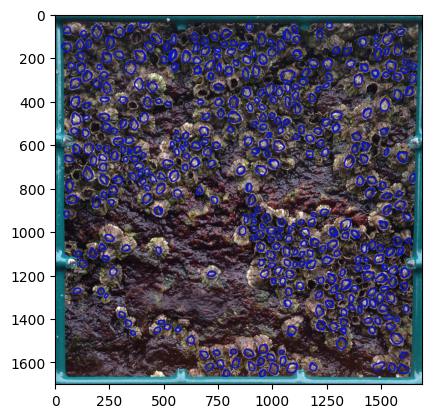

In [43]:
#now, do the operations we did above to second image as well.
img2 = cv2.imread("data/masked_img2.png")
print(img2.shape, img2.dtype, img2.size,img2.min(), img2.max())
#One important information: opencv uses BGR instead of RGB
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
#Convert from BGR to RGB:
plt.imshow(img2_rgb)


## Masking
#Now, we we will proceed with cropping the image and masking to get the ground truth. However, before that, we shall discuss how we can determine a barnacle:
#Barnacles have a sharp, distinctive mouth-like opening. This opening is distinctive in colour compared to the surroundings. 
#Barnacles do not usually touch each other (looking at the mask) but are cumulated in regions together. Hence, there is a high chance that if there is a barnacle, there are other barnacles surrounding it. 
#And size-wise, they are smaller than the rocks surrounding them. 
#However, for our purpose, rather than an object-focused approach, we will implement a pixel-based approach. 
#We will scan through every pixel in an image to determine if they are a part of a barnacle or not, using the ground truth which we will extract. 
#To do so, we will use the masks that were provided to us. 
#The following exercises are more of a way of me learning the process of implementing masks and contours rather than a full analysis. 

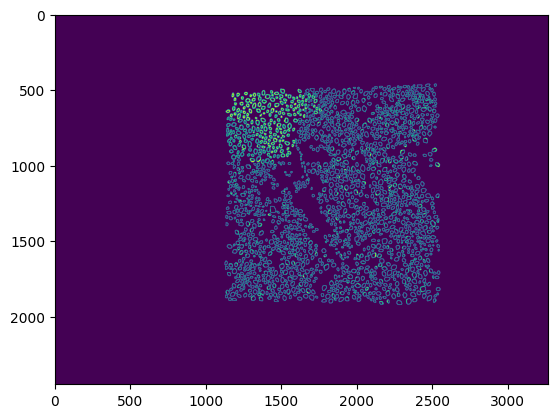

In [44]:
#Now, we determine the mask values
#We can create the mask either by  converting to greyscale or hsv(hue, saturation, value). Hsv gives more flexibility and analysis potential.
#If we were to use a greyscale image, we would have used csv.threshold function. Since we are using hsv, we will follow a different approach. 
#Hue is basically the position of the colour in the colour wheel. cv2 assigns colors values between 0-179.
#Saturation can be thought of as the intensity of the colour. As saturation decreases, colour looks more pale, almost darker. 
maskimg1 = cv2.imread("data/mask1.png")
#Value is the relative lightness/darkness of a colour. 
hsv1 = cv2.cvtColor(maskimg1,cv2.COLOR_BGR2HSV)
#Since we do not know the exact value of blue, we have to estimate it. Blue has a h value of around 120 so we scan that region 
low = np.array([100,80,80])
high = np.array([160,255,255])
#Hence, the mask is:
mask1 = cv2.inRange(hsv1,low,high)
#This result yields a 2D array where pixels that are blue are marked with 255 and other pixels are marked with 0. This is basically equivalent to creating a threshold. 
#We can see that our mask works by using plt.imshow function which allows us to visualise 2d arrays. 
plt.imshow(mask1)
plt.show()


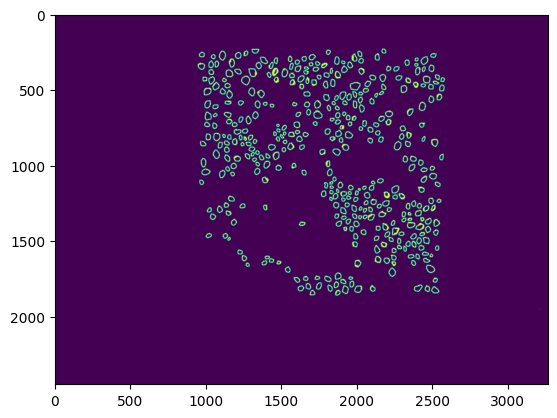

In [45]:
#Do the same operation for image 2
maskimg2 = cv2.imread("data/mask2.png")
hsv2 = cv2.cvtColor(maskimg2,cv2.COLOR_BGR2HSV)
#Since we do not know the exact value of blue, we have to estimate it. Blue has a h value of around 120 so we scan that region 
low = np.array([100,80,80])
high = np.array([160,255,255])
#Hence, the mask is:
mask2 = cv2.inRange(hsv2,low,high)

#We can see that our mask works by using plt.imshow function which allows us to visualise 2d arrays. 
plt.imshow(mask2)
plt.show()

In [46]:
#Now, we create our conotours. Contours are lines that connect a boundary/mask. 
#RETR_EXTERNAL means that opencv2 only scans the external part of the mask to create the contour
#CHAIN_APPROX_SIMPLE is the method of chain approximation that compresses and gets rid of redundant points to save memory. 

contours1,_ = cv2.findContours(mask1, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours2,_ = cv2.findContours(mask2, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

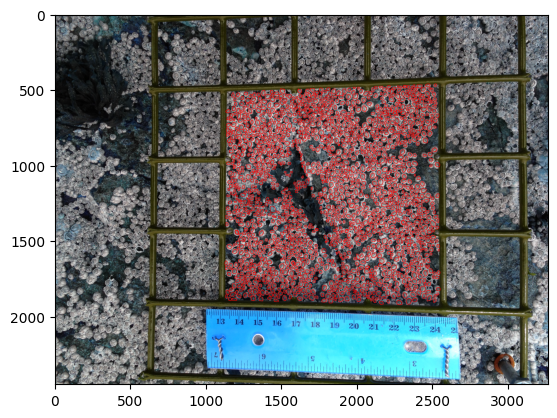

In [47]:
#Now,let's check if our contours are correct. 
unmod1 = cv2.imread("data/img1.png")
pic1 = unmod1.copy()
cv2.drawContours(pic1,contours1,-1,(255,0,0),2)
plt.imshow(pic1)



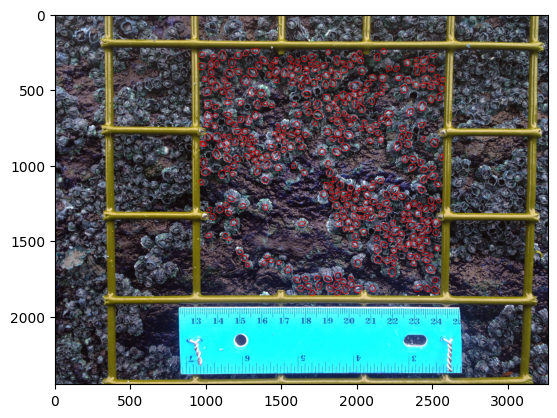

In [48]:
unmod2 = cv2.imread("data/img2.png")
pic2 = unmod2.copy()
cv2.drawContours(pic2,contours2,-1,(255,0,0),2)
plt.imshow(pic2)

##  Contouring and Extracting the Ground Truth
#As we can see, our contours work. As such, we can proceed with extracting the barnacles(ground truth) from the regions bound by contours. 
#For this process, I referred to the following video:
#https://youtu.be/526CbN2ilv8
#By using the contours, we can create masks that will allow us to extract the ground truth inside of them. 

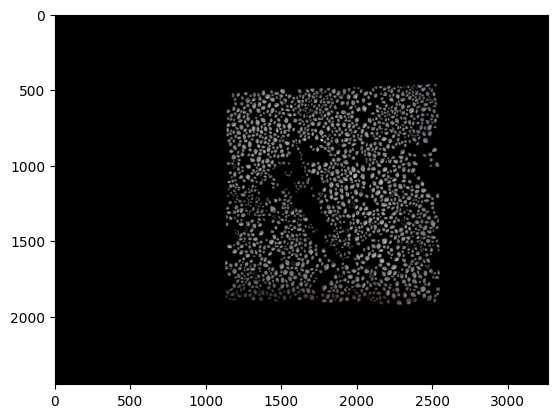

In [49]:

#Creates a mask the same size as pic1
white_mask = np.zeros(unmod1.shape[:2], dtype=np.uint8)
#Draws contours to the mask
cv2.drawContours(white_mask, contours1, -1, (255,255,255),cv2.FILLED)
#Using the white mask that we created, we obtain the foreground(ground truth) of the image. 
#We use cv2.bitwise_and function for that. 
foreground = cv2.bitwise_and(unmod1, unmod1, mask = white_mask)
foreground_rgb = cv2.cvtColor(foreground, cv2.COLOR_BGR2RGB)
plt.imshow(foreground_rgb)



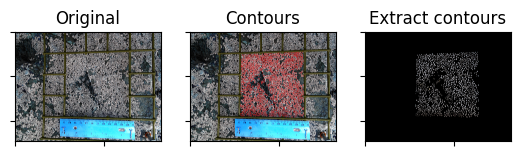

In [50]:
#Now, we can check our original picture, our contours, and the barnacles extracted using contours side by side. 
contours1_dic = {"Original": unmod1, "Contours": pic1, "Extract contours": foreground_rgb }
plt.subplots_adjust(wspace=.2,hspace=.2)
plt.tight_layout()

for i,(key, value) in enumerate(contours1_dic.items()):
    plt.subplot(1,3,i+1)
    plt.tick_params(labelbottom = False)
    plt.tick_params(labelleft = False)
    plt.title("{}".format(key))
    plt.imshow(value)
plt.show()

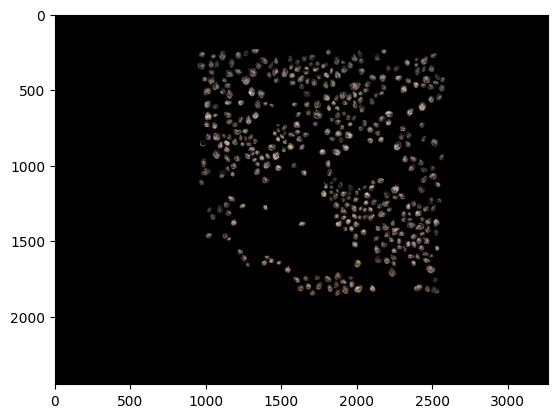

In [51]:
#With this, we can see that we can extract the regions inside the contours. Let us find the barnacles in img2 as well. 
#Creates a mask the same size as pic1
white_mask2 = np.zeros(unmod2.shape[:2], dtype=np.uint8)
#Draws contours to the mask
cv2.drawContours(white_mask2, contours2, -1, (255,255,255),cv2.FILLED)
foreground2 = cv2.bitwise_and(unmod2, unmod2, mask = white_mask2)
foreground_rgb2 = cv2.cvtColor(foreground2, cv2.COLOR_BGR2RGB)
plt.imshow(foreground_rgb2)

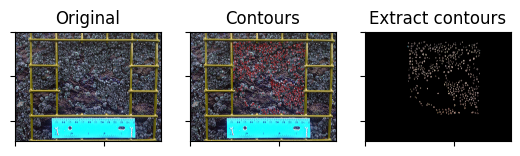

In [52]:
contours2_dic = {"Original": unmod2, "Contours": pic2, "Extract contours": foreground_rgb2 }
plt.subplots_adjust(wspace=.2,hspace=.2)
plt.tight_layout()

for i,(key, value) in enumerate(contours2_dic.items()):
    plt.subplot(1,3,i+1)
    plt.tick_params(labelbottom = False)
    plt.tick_params(labelleft = False)
    plt.title("{}".format(key))
    plt.imshow(value)
plt.show()

## training Random Forest Model
#Now, it is time to train our ML model. Over this summer, I learned about basics of ML with models by learning decision trees, bootstrapping, bagging, and random forests. 
#For my project, I will use random forest model to train my model. I will use scikit-learn for my project. 
#Before doing that, we have to make adjustments on our data so that it can be feed into the model. 
#scikit requires our X-label to have a 2D array-like structure whilst our Y-label hould have 1D array-like structure. 
#X-label should contain samples and features whilst Y-label contains number of samples
#We have to analyse the image pixel-by pixel to determine if it is a part of the barnacle or not. 

In [53]:

#Let us start by identifying the shape of our arrays. 
print(unmod1.shape)
#This means that we have a 3D array with 2448 rows(height), 3264 columns(width), and 3 colour channels
#Hence, we have to reshape our data. we want our array to be 2D and have 3 columns.
X_mod = unmod1.reshape(-1,3)
print(X_mod.shape)
#Now, we should modify the extracted contours(ground truths). We will use the mask to determine the exact regions. 
#We can say that if a pixel is a part of barnacle, it should return 1 and 0 otherwise. 
print(white_mask.shape)
height, width = white_mask.shape
y_train = np.zeros((height,width), dtype=np.uint8)

for i in range(height):
    for j in range(width):
        if white_mask[i,j]==0:
            y_train[i,j] = 0 
        else:
            y_train[i,j] = 1

y_train = y_train.reshape(-1)
print(y_train.shape)


(2448, 3264, 3)
(7990272, 3)
(2448, 3264)
(7990272,)


In [54]:
#Now, do the same for the second image 
print(unmod2.shape)
X_mod2 = unmod2.reshape(-1,3)
print(X_mod2.shape)

height2, width2= white_mask2.shape
y_train2 = np.zeros((height2,width2), dtype=np.uint8)

for i in range(height2):
    for j in range(width2):
        if white_mask2[i,j]==0:
            y_train2[i,j] = 0 
        else:
            y_train2[i,j] = 1
y_train2 = y_train2.reshape(-1)
print(y_train2.shape)

(2448, 3264, 3)
(7990272, 3)
(7990272,)


In [55]:
#To train our model, we have to merge the X and y datas of two images
X_train = np.concatenate((X_mod, X_mod2),axis = 0)
print(X_train.shape)
y_final = np.concatenate((y_train, y_train2), axis = 0)
print(y_final.shape)

#Since we will have a massive amount of data, we leave max_depth as None for now. 
#My number of estimators will be 100. 
clf = RandomForestClassifier(n_estimators = 100, max_depth = None, random_state=44)
clf.fit(X_train, y_final)

(15980544, 3)
(15980544,)


RandomForestClassifier(random_state=44)

In [56]:
#Now, we test our model at unseen images. At first, we need to convert unseen images into a form the model can test on. 
unseen1 = cv2.imread("data/unseen_img1.png")
unseen2 = cv2.imread("data/unseen_img2.png")
print(unseen1.shape)
print(unseen2.shape)
X_t1 = unseen1.reshape(-1,3)
X_t2 = unseen2.reshape(-1,3)

#Now, put these into the model:
pred1 = clf.predict(X_t1)
pred2 = clf.predict(X_t2)


(2448, 3264, 3)
(500, 500, 3)


(2448, 3264)


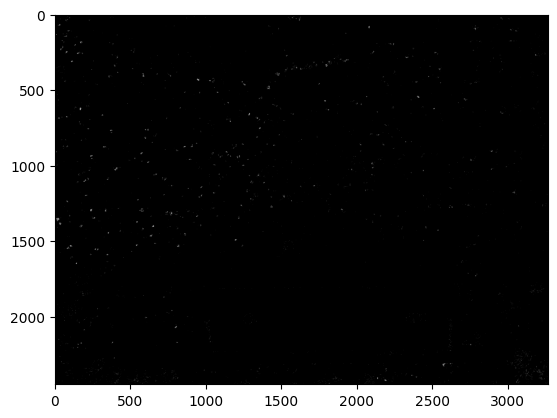

In [57]:
#Now, we have to convert the y-values into an array shape that can be used in opencv2 so that we can test it. 
heightpred, widthpred, _ = unseen1.shape
predmask = pred1.reshape(heightpred, widthpred)
print(predmask.shape)
plt.imshow(predmask, cmap='gray')


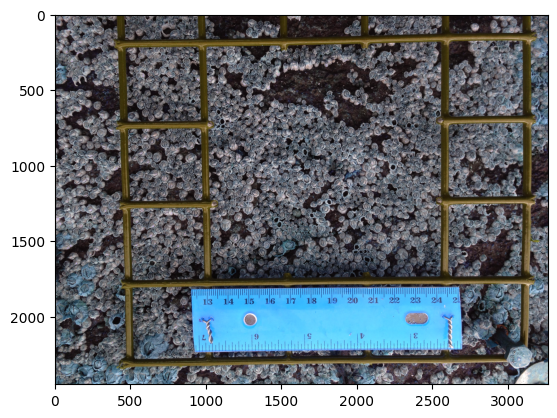

In [58]:
#Now, we test the mask. I will create an opaque mask that will overlap with the image so that we can see if the mask created by our model fits the image. 
overlay = np.zeros_like(unseen1)
overlay[:] = (0, 0, 255)
try1 = cv2.bitwise_and(overlay,overlay, mask=predmask)
output = cv2.addWeighted(unseen1, 1, try1, 1, 0)
plt.imshow(output)

(500, 500)


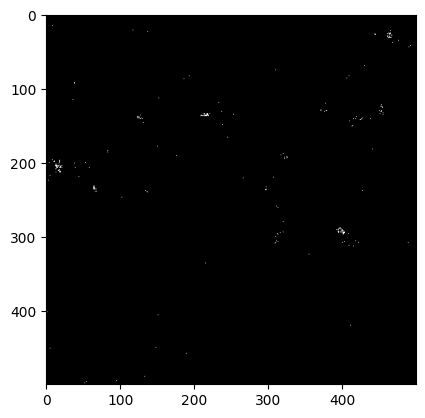

In [59]:
#Now, let's follow the same process for prediction 2. 
heightpred2, widthpred2, _ = unseen2.shape
predmask2 = pred2.reshape(heightpred2, widthpred2)
print(predmask2.shape)
plt.imshow(predmask2, cmap='gray')

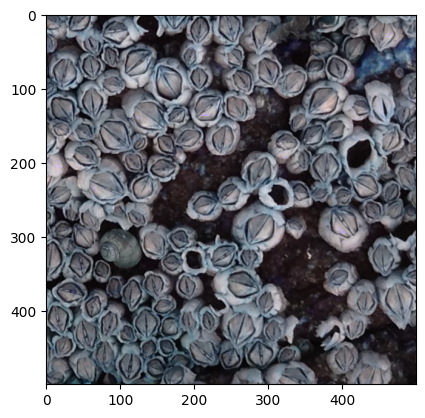

In [60]:

overlay2 = np.zeros_like(unseen2)
overlay2[:] = (0, 0, 255)
try2 = cv2.bitwise_and(overlay2,overlay2, mask=predmask2)
output2 = cv2.addWeighted(unseen2, 1, try2, 1, 0)
plt.imshow(output2)

## Results
While it is not obvious, when we zoom in to the image for output 1, we can see that it marked some of the barnacles correctly. 
The problem is that the model missed majority of the barnacles that are observable in the image
For second image, while it marked some points, they are often far away from the barnacles themselves. 
One possible reason for that is the differences in hsv between the training data that and input image that was later provided to the model. 
#The main reason for both of the problems is that is our model does not have enough pictures and hence enough barnacles to decide if one is a barnacle or not. 
#If we could increase the amount of images of barnacles with masks, there is a higher chance that we are going to obtain better results. 
#This is becase as we have more images, barnacles, and hence pixels, the model will be able to better identify those barnacles. 
#We can also test the accuracy of this model better by using accuracy_score() function. However, we will obtain a really high number sincewe don't have enough data. 
#regardless, seeing that the model visibly identifies barnacles right in the first model tells us that it is worth pursing as a project. 
#If I had a direct connection to the team, I would ask for more annotated pictures and train model that way. Moreover, if I had more data, I would follow a more functional approach of coding that would make the program more usable. As an example, I convetrt my code for obtaining modified X/y values into a function so that it is more usable. 

## What I learned
#When I first started the project, I knew nothing about image processing and opencv. I really appreciate this project for allowing me to learn this process that is really helpful. The process of masking and contours is really useful and excited me a lot. I also didn't know about HSV, RGB/BGR, and grayscaling which is a really essential information in general. I also felt excited to apply some of my experience in machine learning models.